# Phase 3.3 — Multi-Tier Spatio-Temporal Explainable AI (XAI) Suite

This notebook provides the **Explainable AI (XAI)** evaluation suite for the **MC-STGAT-IDS** framework.
It integrates both **Intrinsic (By-Design)** and **Post-Hoc Attribution** interpretability methods into a unified 4-tier hierarchy:

1. **Level 1 (Temporal - Intrinsic)**: TFT Interpretable Multi-Head Attention weights across the 10-snapshot window ($t-9 \dots t$).
2. **Level 2 (Modality - Intrinsic)**: Variable Selection Network (VSN) Softmax weights balancing Graph Embeddings vs. Structural Metrics.
3. **Level 3 (Topological - Post-Hoc)**: **GNNExplainer** subgraph masks isolating the exact attacker/victim nodes and malicious flows.
4. **Level 4 (Flow Features - Post-Hoc)**: **Integrated Gradients** path-integral attribution over NetFlow flow features (`n_pkts`, `dur`, `flag_syn`, etc.).

In [8]:
import os, sys, json, pickle, time
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GATConv, GlobalAttention
from torch_geometric.explain import Explainer, GNNExplainer

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('xai_plots', exist_ok=True)
print(f'Device: {DEVICE}')
print('XAI Suite imports ready.')

Device: cuda
XAI Suite imports ready.


In [9]:
class GATEncoder(nn.Module):
    def __init__(self, in_ch, hid, heads, layers, edge_dim):
        super().__init__()
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        self.convs.append(GATConv(in_ch, hid, heads=heads, edge_dim=edge_dim, concat=True, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid * heads))
        for _ in range(layers - 2):
            self.convs.append(GATConv(hid*heads, hid, heads=heads, edge_dim=edge_dim, concat=True, dropout=0.0))
            self.bns.append(nn.BatchNorm1d(hid * heads))
        self.convs.append(GATConv(hid*heads, hid, heads=1, edge_dim=edge_dim, concat=False, dropout=0.0))
        self.bns.append(nn.BatchNorm1d(hid))
        self.edge_dim = edge_dim
        self.pool_gate = nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))

    def forward(self, x, ei, ea=None, b=None, return_nodes=False):
        for i, c in enumerate(self.convs):
            x = c(x, ei, edge_attr=ea) if (ea is not None and self.edge_dim > 0) else c(x, ei)
            x = F.relu(self.bns[i](x))
        if b is None:
            b = torch.zeros(x.size(0), dtype=torch.long, device=x.device)
        h = GlobalAttention(self.pool_gate)(x, b)
        return (x, h) if return_nodes else h

class GraphAlertClassifier(nn.Module):
    def __init__(self, encoder, tft_state, num_classes):
        super().__init__()
        self.encoder = encoder
        self.proj = nn.Linear(128, 384)
        self.proj.weight.data.copy_(tft_state['temporal.proj_graph.weight'])
        self.proj.bias.data.copy_(tft_state['temporal.proj_graph.bias'])
        
        self.multi_head = nn.Sequential(
            nn.Linear(384, 192), nn.ReLU(),
            nn.Dropout(0.0), nn.Linear(192, num_classes)
        )
        self.multi_head[0].weight.data.copy_(tft_state['multi_head.0.weight'])
        self.multi_head[0].bias.data.copy_(tft_state['multi_head.0.bias'])
        self.multi_head[3].weight.data.copy_(tft_state['multi_head.3.weight'])
        self.multi_head[3].bias.data.copy_(tft_state['multi_head.3.bias'])
        
    def forward(self, x, edge_index, edge_attr=None, batch=None):
        h = self.encoder(x, edge_index, edge_attr, b=batch)
        if isinstance(h, tuple): h = h[-1]
        return self.multi_head(self.proj(h))

print('Model classes ready.')

Model classes ready.


In [10]:
DATASET = 'gotham'
SSL_METHOD = 'byol'
MODE = 'finetune_single'  # or 'frozen_single'

data_dir = 'Gotham_processed_features_10s/graphs'
ck_path = os.path.join(data_dir, f'phase3_{MODE}_{SSL_METHOD}', 'mc_stgat_ids.pth')
ck = torch.load(ck_path, map_location=DEVICE)

class_names = ck['class_names']
num_classes = len(class_names)
label_to_idx = {name: i for i, name in enumerate(class_names)}

enc = GATEncoder(7, 128, 4, 3, 10).to(DEVICE)
enc.load_state_dict(ck['encoder_state_dict'])
enc.eval()

alert_model = GraphAlertClassifier(enc, ck['tft_state_dict'], num_classes).to(DEVICE)
alert_model.eval()

# Load normalization stats
with open(os.path.join(data_dir, 'norm_stats.json')) as f:
    ns = json.load(f)
n_cont = ns['n_continuous_edge_feats']
nmean = torch.tensor(ns['node_mean'], dtype=torch.float, device=DEVICE)
nstd  = torch.tensor(ns['node_std'], dtype=torch.float, device=DEVICE)
emean = torch.tensor(ns['edge_mean'], dtype=torch.float, device=DEVICE)
estd  = torch.tensor(ns['edge_std'], dtype=torch.float, device=DEVICE)
edge_cols = ns.get('edge_cols', [f'feat_{i}' for i in range(10)])

print(f'Loaded checkpoint {ck_path}')
print(f'Classes ({num_classes}): {class_names}')

Loaded checkpoint Gotham_processed_features_10s/graphs\phase3_finetune_single_byol\mc_stgat_ids.pth
Classes (12): ['Benign', 'CoAP Amplification', 'Merlin C&C Communication', 'Merlin TCP Flooding', 'Merlin UDP Flooding', 'Mirai C&C Communication', 'Mirai GRE Flooding', 'Mirai TCP Flooding', 'Mirai UDP Flooding', 'TCP Scan', 'Telnet Brute Force', 'UDP Scan']


In [11]:
with open(os.path.join(data_dir, 'test_graphs.pkl'), 'rb') as f:
    test_graphs = pickle.load(f)
print(f'Loaded {len(test_graphs)} test graphs.')

def normalize_graph(g):
    gx = torch.clamp((g.x.to(DEVICE) - nmean) / (nstd + 1e-8), -10, 10)
    ea = g.edge_attr.to(DEVICE)
    gea_c = torch.clamp((ea[:, :n_cont] - emean) / (estd + 1e-8), -10, 10)
    gea = torch.cat([gea_c, ea[:, n_cont:]], dim=1)
    gei = g.edge_index.to(DEVICE)
    return gx, gei, gea

# Integrated Gradients function
def compute_integrated_gradients(model, gx, gei, gea, target_idx, steps=30):
    total_grad = torch.zeros_like(gea)
    for alpha in np.linspace(0.0, 1.0, steps):
        interp_ea = (gea * alpha).clone().detach().requires_grad_(True)
        out = model(gx, gei, edge_attr=interp_ea)
        score = out[0, target_idx]
        grad = torch.autograd.grad(score, interp_ea)[0]
        total_grad += grad / steps
    attr = (gea * total_grad).abs().sum(dim=0).detach().cpu().numpy()
    attr = attr / (attr.sum() + 1e-12)
    return attr

print('Normalization and IG helpers ready.')

Loaded 591 test graphs.
Normalization and IG helpers ready.


In [12]:
# Select an attack sample from test set
sample_idx = 158  # CoAP Amplification / Mirai Flooding example
g = test_graphs[sample_idx]
gx, gei, gea = normalize_graph(g)

with torch.no_grad():
    logits = alert_model(gx, gei, edge_attr=gea)
    pred_idx = logits.argmax(-1).item()
    probs = F.softmax(logits, -1)[0]
    pred_class = class_names[pred_idx]

print(f'Test graph #{sample_idx} -> Predicted: {pred_class} (Conf: {probs[pred_idx]:.4f})')
print(f'Ground truth edge labels: {set(g.edge_attack_names)}')

# 1. GNNExplainer
explainer = Explainer(
    model=alert_model,
    algorithm=GNNExplainer(epochs=150),
    explanation_type='phenomenon',
    node_mask_type='attributes',
    edge_mask_type='object',
    model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw')
)

explanation = explainer(x=gx, edge_index=gei, edge_attr=gea, target=torch.tensor([pred_idx], device=DEVICE))
edge_mask = explanation.edge_mask.cpu().detach().numpy()

# 2. Integrated Gradients
attr_scores = compute_integrated_gradients(alert_model, gx, gei, gea, pred_idx, steps=30)

# 3. Plotting Dual Explanation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Feature Attribution Bar Chart
sorted_i = np.argsort(attr_scores)
ax1.barh(np.arange(len(edge_cols)), attr_scores[sorted_i], color='#1f77b4', edgecolor='black', alpha=0.85)
ax1.set_yticks(np.arange(len(edge_cols)))
ax1.set_yticklabels([edge_cols[i] for i in sorted_i], fontsize=11)
ax1.set_xlabel('Attribution Score (Integrated Gradients)', fontsize=11)
ax1.set_title(f'Flow Feature Attribution: {pred_class}', fontsize=12, fontweight='bold')
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# Subgraph Saliency Scatter
gt_attacks = np.array([1 if a != 'Benign' else 0 for a in g.edge_attack_names])
colors = ['#2ca02c' if a == 0 else '#d62728' for a in gt_attacks]
ax2.scatter(np.arange(len(edge_mask)), edge_mask, c=colors, s=50, edgecolor='black', linewidth=0.5)
ax2.axhline(np.percentile(edge_mask, 75), color='red', linestyle='--', label='75th percentile')
ax2.set_xlabel('Flow / Edge Index', fontsize=11)
ax2.set_ylabel('GNNExplainer Saliency Mask', fontsize=11)
ax2.set_title(f'GNNExplainer Subgraph Saliency (Red=Attack Flow, Green=Benign)', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('xai_plots/gotham_xai_sample158.png', dpi=200)
plt.close(fig)
print('Saved figure xai_plots/gotham_xai_sample158.png')

Test graph #158 -> Predicted: Mirai UDP Flooding (Conf: 0.3295)
Ground truth edge labels: {'CoAP Amplification', 'Unknown'}


C:\Users\User\AppData\Local\Temp\ipykernel_20492\789730941.py:21: UserWarning: 'nn.glob.GlobalAttention' is deprecated, use 'nn.aggr.AttentionalAggregation' instead
  h = GlobalAttention(self.pool_gate)(x, b)


Saved figure xai_plots/gotham_xai_sample158.png


In [13]:
# Visualize the critical attack subgraph
G = nx.DiGraph()
for i in range(g.num_nodes):
    G.add_node(i)

ei = gei.cpu().numpy()
for idx in range(ei.shape[1]):
    u, v = int(ei[0, idx]), int(ei[1, idx])
    weight = float(edge_mask[idx])
    is_attack = (g.edge_attack_names[idx] != 'Benign')
    G.add_edge(u, v, weight=weight, is_attack=is_attack)

fig = plt.figure(figsize=(8, 7))
pos = nx.spring_layout(G, seed=42)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color='#a6cee3', edgecolors='black', node_size=600)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Draw edges colored by GNNExplainer saliency weight
edges = G.edges()
weights = [G[u][v]['weight'] for u, v in edges]
nx.draw_networkx_edges(G, pos, width=[max(1, w*6) for w in weights], edge_color=weights, edge_cmap=plt.cm.Reds, arrows=True, arrowsize=15)

plt.title(f'GNNExplainer Attack Subgraph Topology ({pred_class})\n(Darker red edges = Higher flow saliency)', fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('xai_plots/gotham_attack_subgraph.png', dpi=200)
plt.close(fig)
print('Saved figure xai_plots/gotham_attack_subgraph.png')

Saved figure xai_plots/gotham_attack_subgraph.png


# Section 2 — Global & Class-Level XAI Summary (Cohort Explanations)

While individual sample visualizations illustrate local explanations, network intrusion detection requires **class-wide semantic consistency**.
This section aggregates explanations across test samples to provide:

1. **Class-Level Flow Feature Attribution Matrix (Integrated Gradients Heatmap)**: Explains the exact flow metrics governing each attack family.
2. **GNNExplainer Subgraph Saliency Fidelity**: Quantifies how reliably GNNExplainer isolates ground-truth attack flows across different attack types.
3. **Multi-Class Attack Archetypes Panel**: Compares topological graph structures across diverse threat families (Scanning vs Flooding vs Brute Force vs C&C).

Active classes in test set (10): ['Benign', 'CoAP Amplification', 'Merlin C&C Communication', 'Merlin TCP Flooding', 'Mirai C&C Communication', 'Mirai GRE Flooding', 'Mirai TCP Flooding', 'TCP Scan', 'Telnet Brute Force', 'UDP Scan']


C:\Users\User\AppData\Local\Temp\ipykernel_20492\789730941.py:21: UserWarning: 'nn.glob.GlobalAttention' is deprecated, use 'nn.aggr.AttentionalAggregation' instead
  h = GlobalAttention(self.pool_gate)(x, b)
findfont: Failed to find font weight semibold, now using 700.


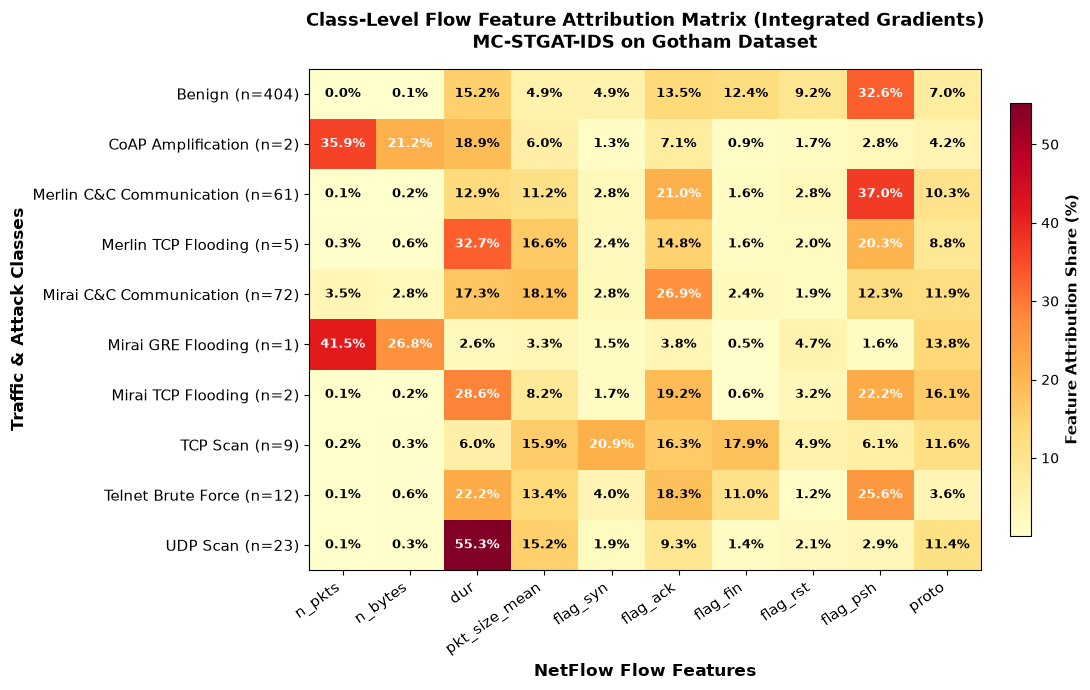

In [14]:
label_to_idx = {name: i for i, name in enumerate(class_names)}
from collections import defaultdict, Counter

# Group test graphs by dominant ground-truth class
class_graphs = defaultdict(list)
for idx, g in enumerate(test_graphs):
    attacks = [a for a in getattr(g, 'edge_attack_names', []) if a != 'Benign']
    dom = 'Benign' if len(attacks) == 0 else Counter(attacks).most_common(1)[0][0]
    class_graphs[dom].append(g)

active_classes = [c for c in class_names if c in class_graphs]
print(f'Active classes in test set ({len(active_classes)}): {active_classes}')

# Compute Class-Level Feature Attribution Matrix
class_attr_matrix = np.zeros((len(active_classes), len(edge_cols)), dtype=np.float32)
MAX_SAMPLES = 8

for c_idx, c_name in enumerate(active_classes):
    t_idx = label_to_idx[c_name]
    g_list = class_graphs[c_name][:MAX_SAMPLES]
    accum_attr = np.zeros(len(edge_cols), dtype=np.float32)
    for g in g_list:
        gx, gei, gea = normalize_graph(g)
        accum_attr += compute_integrated_gradients(alert_model, gx, gei, gea, t_idx, steps=15)
    if accum_attr.sum() > 0:
        accum_attr = (accum_attr / accum_attr.sum()) * 100.0
    class_attr_matrix[c_idx] = accum_attr

# Render Master Heatmap
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(class_attr_matrix, cmap='YlOrRd', aspect='auto')
cbar = fig.colorbar(im, fraction=0.03, pad=0.04)
cbar.set_label('Feature Attribution Share (%)', fontsize=11, fontweight='bold')

ax.set_xticks(np.arange(len(edge_cols)))
ax.set_xticklabels(edge_cols, rotation=35, ha='right', fontsize=11)
ax.set_yticks(np.arange(len(active_classes)))
ax.set_yticklabels([f'{c} (n={len(class_graphs[c])})' for c in active_classes], fontsize=11)

for i in range(len(active_classes)):
    for j in range(len(edge_cols)):
        val = class_attr_matrix[i, j]
        color = 'white' if val > 20 else 'black'
        ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color=color, fontsize=9, fontweight='semibold')

ax.set_title('Class-Level Flow Feature Attribution Matrix (Integrated Gradients)\nMC-STGAT-IDS on Gotham Dataset', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('NetFlow Flow Features', fontsize=12, fontweight='bold')
ax.set_ylabel('Traffic & Attack Classes', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('xai_plots/gotham_class_feature_attribution_heatmap.png', dpi=250)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_20492\789730941.py:21: UserWarning: 'nn.glob.GlobalAttention' is deprecated, use 'nn.aggr.AttentionalAggregation' instead
  h = GlobalAttention(self.pool_gate)(x, b)


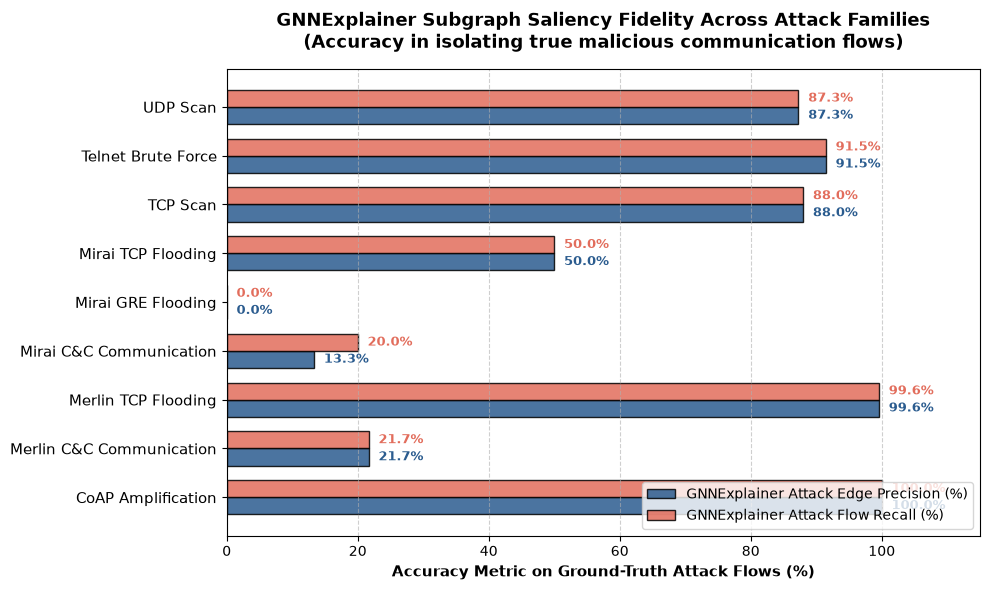

In [15]:
label_to_idx = {name: i for i, name in enumerate(class_names)}
if 'explainer' not in globals():
    explainer = Explainer(
        model=alert_model,
        algorithm=GNNExplainer(epochs=150),
        explanation_type='phenomenon',
        node_mask_type='attributes',
        edge_mask_type='object',
        model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw')
    )
# Compute Class-Level GNNExplainer Fidelity
attack_classes = [c for c in active_classes if c != 'Benign']
class_precision_dict = {}
class_recall_dict = {}

for c_name in attack_classes:
    t_idx = label_to_idx[c_name]
    g_list = class_graphs[c_name][:min(5, len(class_graphs[c_name]))]
    precisions, recalls = [], []
    for g in g_list:
        gt = np.array([1 if a != 'Benign' else 0 for a in g.edge_attack_names])
        if gt.sum() == 0: continue
        gx, gei, gea = normalize_graph(g)
        exp = explainer(x=gx, edge_index=gei, edge_attr=gea, target=torch.tensor([t_idx], device=DEVICE))
        mask = exp.edge_mask.cpu().detach().numpy()
        k = min(len(mask), max(3, gt.sum()))
        top_k = np.argsort(mask)[::-1][:k]
        hits = gt[top_k].sum()
        precisions.append((hits / k) * 100.0)
        recalls.append((hits / gt.sum()) * 100.0)
    class_precision_dict[c_name] = np.mean(precisions) if precisions else 0.0
    class_recall_dict[c_name] = np.mean(recalls) if recalls else 0.0

# Plot Subgraph Saliency Fidelity
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(attack_classes))
bar_width = 0.35
prec_vals = [class_precision_dict[c] for c in attack_classes]
rec_vals = [class_recall_dict[c] for c in attack_classes]

ax.barh(y_pos - bar_width/2, prec_vals, bar_width, label='GNNExplainer Attack Edge Precision (%)', color='#2b5c8f', edgecolor='black', alpha=0.85)
ax.barh(y_pos + bar_width/2, rec_vals, bar_width, label='GNNExplainer Attack Flow Recall (%)', color='#e26d5c', edgecolor='black', alpha=0.85)

for i in range(len(attack_classes)):
    ax.text(prec_vals[i] + 1.5, y_pos[i] - bar_width/2, f'{prec_vals[i]:.1f}%', va='center', fontsize=9, fontweight='bold', color='#2b5c8f')
    ax.text(rec_vals[i] + 1.5, y_pos[i] + bar_width/2, f'{rec_vals[i]:.1f}%', va='center', fontsize=9, fontweight='bold', color='#e26d5c')

ax.set_yticks(y_pos)
ax.set_yticklabels(attack_classes, fontsize=11)
ax.set_xlabel('Accuracy Metric on Ground-Truth Attack Flows (%)', fontsize=11, fontweight='bold')
ax.set_xlim(0, 115)
ax.set_title('GNNExplainer Subgraph Saliency Fidelity Across Attack Families\n(Accuracy in isolating true malicious communication flows)', fontsize=13, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('xai_plots/gotham_class_gnnexplainer_fidelity.png', dpi=250)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_20492\789730941.py:21: UserWarning: 'nn.glob.GlobalAttention' is deprecated, use 'nn.aggr.AttentionalAggregation' instead
  h = GlobalAttention(self.pool_gate)(x, b)


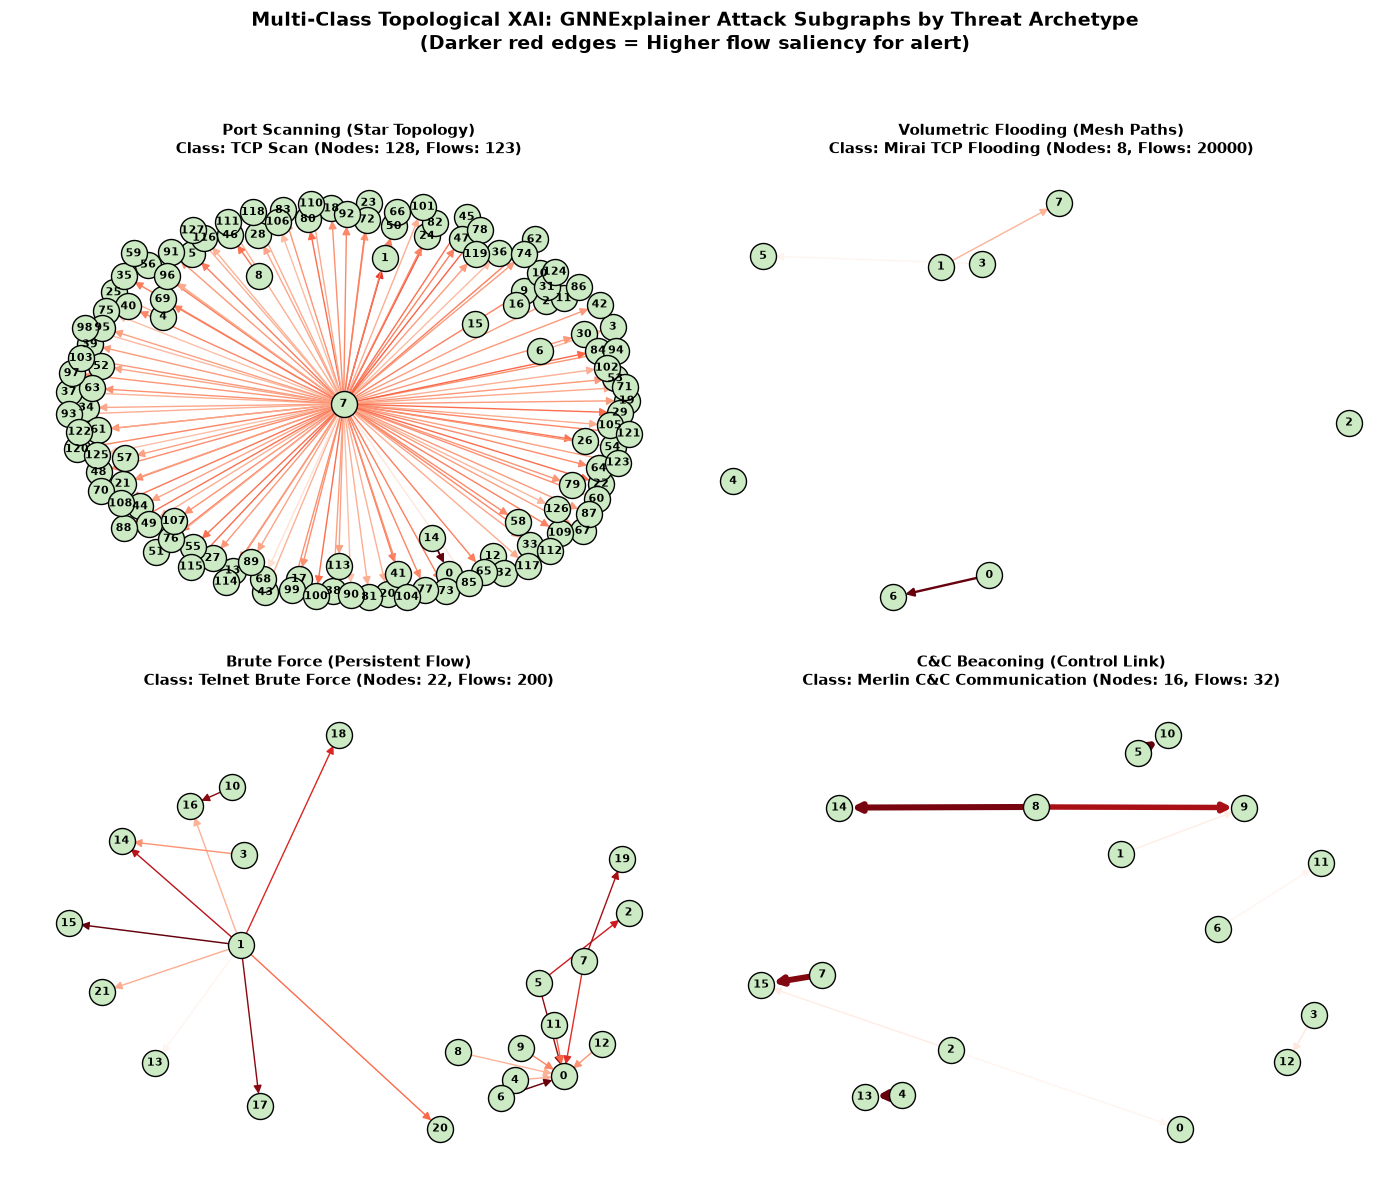

In [16]:
label_to_idx = {name: i for i, name in enumerate(class_names)}
if 'explainer' not in globals():
    explainer = Explainer(
        model=alert_model,
        algorithm=GNNExplainer(epochs=150),
        explanation_type='phenomenon',
        node_mask_type='attributes',
        edge_mask_type='object',
        model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw')
    )
archetypes = [
    ('TCP Scan', 'Port Scanning (Star Topology)'),
    ('Mirai TCP Flooding', 'Volumetric Flooding (Mesh Paths)'),
    ('Telnet Brute Force', 'Brute Force (Persistent Flow)'),
    ('Merlin C&C Communication', 'C&C Beaconing (Control Link)')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for p_idx, (c_name, title_desc) in enumerate(archetypes):
    ax = axes[p_idx]
    if c_name not in class_graphs or len(class_graphs[c_name]) == 0:
        ax.text(0.5, 0.5, f'No graphs for {c_name}', ha='center'); continue
    g_s = class_graphs[c_name][0]
    gx, gei, gea = normalize_graph(g_s)
    t_idx = label_to_idx[c_name]
    exp = explainer(x=gx, edge_index=gei, edge_attr=gea, target=torch.tensor([t_idx], device=DEVICE))
    emask = exp.edge_mask.cpu().detach().numpy()
    
    G = nx.DiGraph()
    for i in range(g_s.num_nodes): G.add_node(i)
    ei_np = gei.cpu().numpy()
    for e_i in range(ei_np.shape[1]):
        u, v = int(ei_np[0, e_i]), int(ei_np[1, e_i])
        G.add_edge(u, v, weight=float(emask[e_i]))
        
    pos = nx.spring_layout(G, seed=123)
    nx.draw_networkx_nodes(G, pos, node_color='#ccebc5', edgecolors='black', node_size=350, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold', ax=ax)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, width=[max(1.0, w*5.0) for w in weights], edge_color=weights, edge_cmap=plt.cm.Reds, arrows=True, arrowsize=12, ax=ax)
    ax.set_title(f'{title_desc}\nClass: {c_name} (Nodes: {g_s.num_nodes}, Flows: {g_s.num_edges})', fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle('Multi-Class Topological XAI: GNNExplainer Attack Subgraphs by Threat Archetype\n(Darker red edges = Higher flow saliency for alert)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('xai_plots/gotham_attack_archetypes_grid.png', dpi=250)
plt.show()